# Create regression input dataset for payroll model

In [1]:
import xarray as xr
import xesmf as xe
import xagg as xa 
import numpy as np
import pandas as pd
import geopandas as gpd
import xhistogram.xarray as xhist
from tqdm.notebook import tqdm
import os
import re
import glob
import fsspec
import copy
import shutil
from matplotlib import pyplot as plt
from cartopy import crs as ccrs

from numba import jit as njit

from funcs_support import utility_save,get_params,get_filepaths
from funcs_aux import _restore_doys
dir_list = get_params()
# Get filesystem
fs = fsspec.implementations.local.LocalFileSystem()

In [2]:
from distributed import Client
client = Client()
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /node/crhtc14.hpc.ucar.edu/64094/proxy/8787/status,
Dashboard: /node/crhtc14.hpc.ucar.edu/64094/proxy/8787/status,Workers: 6
Total threads: 18,Total memory: 144.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:42537,Workers: 0
Dashboard: /node/crhtc14.hpc.ucar.edu/64094/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:40933,Total threads: 3
Dashboard: /node/crhtc14.hpc.ucar.edu/64094/proxy/33421/status,Memory: 24.00 GiB
Nanny: tcp://127.0.0.1:37555,


2026-10-19 13:36:29,776 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 44f2ca9cdc56f59cc1ecde18a5608207 initialized by task ('rechunk-merge-rechunk-transfer-174ade073aa3fab4e584dd2ba026db51', 0, 0, 0, 0, 0, 0, 9, 0) executed on worker tcp://127.0.0.1:36669
2026-10-19 13:36:32,971 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 44f2ca9cdc56f59cc1ecde18a5608207 deactivated due to stimulus 'task-finished-1792438592.9697514'
2026-10-19 13:36:33,071 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 8337b44512cb1e8f537c7ce9f852ff6f initialized by task ('rechunk-merge-rechunk-transfer-c6202d4dab433a342ecd1bc43de08cc0', 0, 0, 0, 0, 0, 0, 0, 0) executed on worker tcp://127.0.0.1:44889
2026-10-19 13:36:36,115 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 8337b44512cb1e8f537c7ce9f852ff6f deactivated due to stimulus 'task-finished-1792438596.1128807'
2026-10-19 13:36:39,736 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 44f2ca9cdc56f59c

In [3]:
# US Counties
gdf = gpd.read_file(dir_list['aux']+'geo_data/UScounties.shp')

# Histogram parameters
# In F
bin_width = 5
bins = np.arange(-50,131,bin_width)

params_subset = {'lat':slice(23,53),'lon':slice(-127,-60)}
# Get reference 0.25x0.25 grid that slots into the 
# ref_grid 1x1 grid perfectly 
coarse_grid = xr.Dataset(coords = {'lat':(['lat'],np.arange(params_subset['lat'].start+0.5,
    														 params_subset['lat'].stop-0.4)),
     								'lon':(['lon'],np.arange(params_subset['lon'].start+0.5,
    														 params_subset['lon'].stop-0.4))})

fine_grid = xr.Dataset(coords = {'lat':(['lat'],np.arange(params_subset['lat'].start+0.125,
														 params_subset['lat'].stop-0.124,0.25)),
								'lon':(['lon'],np.arange(params_subset['lon'].start+0.125,
														 params_subset['lon'].stop-0.124,0.25))})

var = 'tasmax'


# Load population by grid cell
pop_fn = dir_list['aux']+'pop_data/pop_fx_LANDSCAN_conus_day_025deg_2016.nc'
if not fs.exists(pop_fn):
    pop = xr.open_dataset(dir_list['aux']+'pop_data/landscan-usa-2016-conus-day.tif')
    pop = xa.fix_ds(pop.isel(band=0).rename({'band_data':'pop'})).coarsen({'lat':300,'lon':300}).sum()
    pop['lat'] = np.round(pop['lat'],3) # floating point errors otehrwise
    pop['lon'] = np.round(pop['lon'],3)
    pop.attrs['SOURCE'] = '1c_create_reginput_payroll.ipynb'
    pop.attrs['DESCRIPTION'] = 'landscan USA 2016 daytime CONUS data, coarsened (by summing) 300x to a 0.25-deg grid'
    utility_save(pop,pop_fn)
else:
    pop = xr.open_dataset(pop_fn)


In [4]:
# Get weightmap between reference grid and counties
wm = {'fine':{'raw':xa.pixel_overlaps(fine_grid,gdf),
      'pop':xa.pixel_overlaps(fine_grid,gdf,weights=pop.pop)},
      'coarse':{'raw':xa.pixel_overlaps(coarse_grid,gdf),
      'pop':xa.pixel_overlaps(coarse_grid,gdf,weights=pop.pop)}}

creating polygons for each pixel...
lat/lon bounds not found in dataset; they will be created.
calculating overlaps between pixels and output polygons...
success!
creating polygons for each pixel...
regridding weights to data grid...


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xagg/core.py:192: UserWarning: The `weights` input (bbox latmin, latmax, lonmin, lonmax: 24.375, 49.375, -124.875, -66.875 spans less area than the `ds` input (bbox: 23.125, 52.875, -126.875, -60.125). Weights beyond  this bounding box may be set to 0 or incorrectly interpolated.
  warnings.warn('The `weights` input (bbox latmin, latmax, lonmin, lonmax: '+


calculating overlaps between pixels and output polygons...
success!
creating polygons for each pixel...
lat/lon bounds not found in dataset; they will be created.
calculating overlaps between pixels and output polygons...
success!
creating polygons for each pixel...
regridding weights to data grid...


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/xagg/core.py:192: UserWarning: The `weights` input (bbox latmin, latmax, lonmin, lonmax: 24.375, 49.375, -124.875, -66.875 spans less area than the `ds` input (bbox: 23.5, 52.5, -126.5, -60.5). Weights beyond  this bounding box may be set to 0 or incorrectly interpolated.
  warnings.warn('The `weights` input (bbox latmin, latmax, lonmin, lonmax: '+


calculating overlaps between pixels and output polygons...
success!


In [5]:
@njit
def numba_histogram(data, bins):
    hist = np.zeros(len(bins) - 1, dtype=np.int64)
    for value in data:
        for i in range(len(bins) - 1):
            if bins[i] <= value < bins[i + 1]:
                hist[i] += 1
                break
    return hist

def fast_histogram(da, bins, dim):
    return xr.apply_ufunc(
        numba_histogram,
        da,
        input_core_dims=[dim],
        output_core_dims=[['bin']],
        kwargs={'bins': bins},
        vectorize=True,
        dask="parallelized",
        output_dtypes=[int],
        dask_gufunc_kwargs = {'output_sizes':{'bin':len(bins)-1}}
    )

In [6]:
# Load sample dataset
# (originally "Replication_data.csv" from hle_repl_ab/Data, uploaded and renamed)
df_sample = pd.read_csv(dir_list['aux']+'hle_replication_data.csv')
year_range = (df_sample.year.min(),df_sample.year.max())

In [14]:
df = get_filepaths()
df = df.query('((suffix != suffix) or (suffix == "CONUS") or (suffix == "025"))')

pr_sub_list = ['BEST','NLDAS','nClim-Grid','PRISM-Schlenker','Daymet']
pr_sub_mod = 'PRISM'

obs_mod_list = ['ERA5-025','MERRA2','JRA-3Q','GMFD','PRISM',
                'ERA5-025-1deg','MERRA2-1deg','JRA-3Q-1deg','GMFD-1deg','PRISM-1deg',
                'NLDAS','nClim-Grid','PRISM-Schlenker','Daymet',
                ]

dss_out_all = []

for obs_mod in tqdm(obs_mod_list):
    print(f'\nProcessing {obs_mod}')

    df_tmp = df.query(f'model == "{obs_mod}" and (varname == "tasmax" or varname == "pr") and freq == "day"')
    if obs_mod in pr_sub_list:
        df_tmp = pd.concat([df_tmp,
                            df.query(f'model == "{pr_sub_mod}" and varname == "pr" and freq == "day"')])
    
    fn_in = {v:df_tmp.query(f'varname == "{v}"').iloc[0]['path']
         for v in [var,'pr']}
    # Load
    print(f'Using files {', '.join([v for k,v in fn_in.items()])}...')
    
    dss_out_tmp = []
    for v in fn_in:
        fn = fn_in[v]
        if '.zarr' in fn:
            ds = xr.open_zarr(fn)
        else:
            ds = xr.open_dataset(fn)
    
        # Subset to just needed years
        ds = ds.sel(time=slice(str(year_range[0]),str(year_range[1])))
    
        # Subset to CONUS
        ds = ds.sel(**params_subset)
    
        if '.zarr' in fn:
            # Rechunk for regridding
            if obs_mod in ['PRISM','PRISM-Schlenker','NLDAS','Daymet','nClim-Grid']:
                # So high resolution, need to make sure this is a dask array 
                # with small chunks for regridding
                ds = ds.chunk({'lat':-1,'lon':-1,'time':50})
            else:
                ds = ds.chunk({'lat':-1,'lon':-1,'time':500})
        
            fn_tmp = re.sub(r'\.zarr','_RECHK-TMP.zarr',fn)
            utility_save(ds.drop_encoding(),fn_tmp,zarr_mode = 'w',raw_overwrite_flag=True)
            ds = xr.open_zarr(fn_tmp)
    
    
        # Regrid to 0.25 deg grid
        if '1deg' not in obs_mod:
            rgrd = xe.Regridder(ds,fine_grid,'bilinear')
            ds = rgrd(ds)
            if v == 'tasmax':
                # Make sure areas that don't overlap with destination grid
                # are nan, not 0 (T in K can't be 0)
                ds[v] = ds[v].where(ds[var]!=0)
            else:
                ds[v] = ds[v].where(ds[v].sum('time')!=0)
    
        if obs_mod == 'PRISM':
            # Now need to rechunk such that time is one chunk
            ds = ds.chunk({'lat':20,'lon':20,'time':-1})
        
        # Reshape to dayofyear x year 
        ds = ds.assign_coords({'year':ds.time.dt.year,
                    'dayofyear':ds.time.dt.dayofyear})
        
        ds = ds.set_index(time=['dayofyear','year']).unstack()
    
        # For some reason, this did not make dayofyear one chunk above 
        ds = ds.chunk({'lat':20,'lon':20,'dayofyear':-1,'year':-1})
    
        if v == var:
            # Calculate histogram
            ds = fast_histogram(ds[var],bins=(bins-32)*5/9+273.15,dim=['dayofyear'])
            ds['bin'] = bins[0:-1]+bin_width/2
        elif v == 'pr':
            # Calculate annual precip
            ds = ds['pr'].mean('dayofyear')
    
        # Aggregate
        with xa.set_options(impl='numba'):
            if '1deg' in obs_mod:
                agg = {typ:xa.aggregate(ds.chunk({'lat':-1,'lon':-1,'year':1}),copy.deepcopy(wm['coarse'][typ])) for typ in wm['coarse']}
            else:
                agg = {typ:xa.aggregate(ds.chunk({'lat':-1,'lon':-1,'year':1}),copy.deepcopy(wm['fine'][typ])) for typ in wm['fine']}
    
        # Get out in xarray dataset format
        dss_out = {typ:ag.to_dataset() for typ,ag in agg.items()}
    
        dss_out = xr.concat([dss_out[typ][v].expand_dims({'weighting':[typ],'model':[obs_mod]})
                               for typ in dss_out],
                              dim='weighting')
    
        dss_out_tmp.append(dss_out)

        if 'zarr' in fn:
            print('Removing tmp file...')
            shutil.rmtree(fn_tmp)
    dss_out_all.append(xr.merge(dss_out_tmp))

    


Processing Daymet
Using files /glade/derecho/scratch/schwarzwald/climate_raw_derecho/Daymet/tasmax_day_Daymet_historical_observations_19800101-20101231_CONUS-025.nc, /glade/derecho/scratch/schwarzwald/climate_raw_derecho/PRISM/pr_day_PRISM_historical_obs_1981010101-20260630_CONUS.zarr...
adjusting grid... (this may happen because only a subset of pixels were used for aggregation for efficiency - i.e. [subset_bbox=True] in xa.pixel_overlaps())
grid adjustment successful
aggregating tasmax...


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 1.10 GiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


all variables aggregated to polygons!
adjusting grid... (this may happen because only a subset of pixels were used for aggregation for efficiency - i.e. [subset_bbox=True] in xa.pixel_overlaps())
grid adjustment successful
aggregating tasmax...


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 1.10 GiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


all variables aggregated to polygons!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


/glade/derecho/scratch/schwarzwald/climate_raw_derecho/PRISM/pr_day_PRISM_historical_obs_1981010101-20260630_CONUS_RECHK-TMP.zarr saved!
adjusting grid... (this may happen because only a subset of pixels were used for aggregation for efficiency - i.e. [subset_bbox=True] in xa.pixel_overlaps())
grid adjustment successful
aggregating pr...
all variables aggregated to polygons!
adjusting grid... (this may happen because only a subset of pixels were used for aggregation for efficiency - i.e. [subset_bbox=True] in xa.pixel_overlaps())
grid adjustment successful
aggregating pr...
all variables aggregated to polygons!
Removing tmp file...


/glade/derecho/scratch/schwarzwald/tmp/ipykernel_11855/73686339.py:106: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'year' ('year',) The recommendation is to set join explicitly for this case.
  dss_out_all.append(xr.merge(dss_out_tmp))


In [18]:
dss_out_all = xr.concat(dss_out_all,dim='model',join='outer')

In [28]:
# Sync up nans between pr and tasmax
dss_out_all['pr'] = dss_out_all['pr'].where(~dss_out_all['tasmax'].isel(bin=0).mean('poly_idx').isnull())

In [29]:
# Add back in other metadata 
other_vars = agg['raw'].to_dataset()
other_vars = other_vars[[v for v in other_vars if v not in ['pr',var]]]
dss_out_all = xr.merge([dss_out_all.rename({var:var+'bins'}),
                        other_vars])


In [31]:
convert_mods = [mod for mod in dss_out_all.model.values if mod not in ['PRISM','PRISM-1deg']]


In [18]:
#dss_out_all = xr.concat(dss_out_all,dim='model',join='outer')

# Add back in other metadata 
other_vars = agg['raw'].to_dataset()
other_vars = other_vars[[v for v in other_vars if v not in ['pr',var]]]
dss_out_all = xr.merge([dss_out_all.rename({var:var+'bins'}),
                        other_vars])

convert_mods = [mod for mod in dss_out_all.model.values if mod not in ['PRISM','PRISM-1deg',*pr_sub_list]]
# To mm/day, for consistency with original (PRISM already in mm/day)
dss_out_all['pr'].loc[{'model':convert_mods}] = dss_out_all['pr'].loc[{'model':convert_mods}]*60*60*24

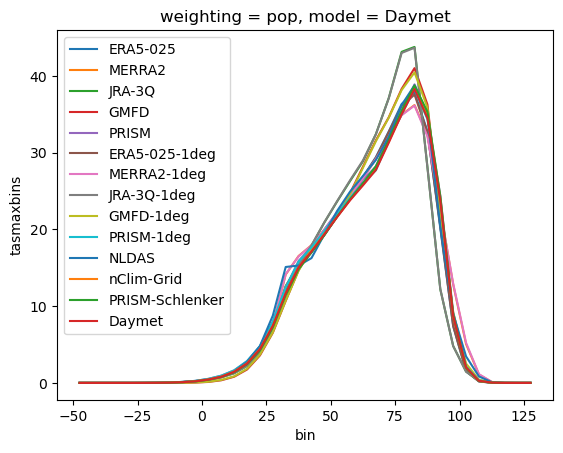

In [79]:
ax = plt.subplot()
for mod in dss_out_all.model.values:
    dss_out_all.sel(model=mod,weighting='pop').mean('poly_idx').tasmaxbins.mean('year').plot(label=mod)
ax.legend()

In [80]:
# Subset to just the relevant bins + index variables, renamed as in sample df
dss_out_all = dss_out_all.rename({'pr':'prec_dry'})
dss_out_all = dss_out_all.rename({'FIPS':'fips','STATE_FIPS':'state'})[[var+'bins','prec_dry','fips','state']]
# Turn into int fips to match sample df
for v in ['fips','state']:
    dss_out_all[v] = dss_out_all[v].astype(int)

In [101]:
for weighting in dss_out_all.weighting.values:
    # Extract data for model / weighting scheme
    ds_tmp = dss_out_all.sel(weighting = weighting,drop=True)
    
    # Get binwidths (for bin column naming)
    ds_tmp['bindiffs'] = ds_tmp['bin'].diff('bin')
    
    # Sum below 40 and above 90 to their own variables
    ds_tmp['days90plus_dry'] = ds_tmp[var+'bins'].sel(bin = slice(90,None)).sum('bin')
    ds_tmp['days95plus_dry'] = ds_tmp[var+'bins'].sel(bin = slice(95,None)).sum('bin')
    ds_tmp['days100plus_dry'] = ds_tmp[var+'bins'].sel(bin = slice(100,None)).sum('bin')
    ds_tmp['below40_dry'] = ds_tmp[var+'bins'].sel(bin = slice(None,40)).sum('bin')
    # Subset to remaining bins
    ds_tmp = ds_tmp.sel(bin=slice(40,100))
    
    # Subset to just needed years
    ds_tmp = ds_tmp.sel(year = np.unique(df_sample.year))
    
    # Change bin dimension to match sample df column names
    ds_tmp['bin'] = [str(int(b-diff/2))+'to'+str(int(b+diff/2)) for b,diff in zip(ds_tmp['bin'],ds_tmp['bindiffs'])]
    
    # Put into dataframe format
    df_bins = (ds_tmp[['fips',var+'bins']].to_dataframe().reset_index().
                 drop('poly_idx',axis=1).
                 set_index(['fips','year','model']))
    df_bins = df_bins.pivot(columns = 'bin',values=var+'bins')
    df_bins.columns = ['FND_'+col+'_dry' for col in df_bins.columns]
    
    # Add 90+, 40- in
    df_bins = df_bins.join((ds_tmp[['fips','prec_dry','days90plus_dry','days95plus_dry','days100plus_dry','below40_dry']].to_dataframe().reset_index().
     drop('poly_idx',axis=1).
     set_index(['fips','year','model'])))
    
    # Add other variables, metadata
    df_out = (df_sample[['fips','year','state','lny_nonag',
                        'Dividends','pc_Div','mean_Div4','mean_Div2','pc_DivL1']].
              set_index(['fips','year']).join(df_bins))
    
    # Rename to match standards
    df_out = df_out.rename_axis(index={'model': 'obs_mod'})

    # Remove rows without data for an obs product
    df_out = df_out.iloc[(~df_out.FND_95to100_dry.isnull()).values,:]
    
    # Split out by 0.25 deg and 1 deg inputs 
    df_out_025deg = df_out.iloc[['1deg' not in m for m in df_out.index.get_level_values('obs_mod')],:]
    df_out_1deg = df_out.iloc[['1deg' in m for m in df_out.index.get_level_values('obs_mod')],:]

    # Make the model names identical , without the "1deg" attachment
    df_out_1deg = df_out_1deg.reset_index()
    df_out_1deg['obs_mod'] = [re.sub(r'\-1deg','',pb) for pb in df_out_1deg['obs_mod'].values]
    df_out_1deg = df_out_1deg.set_index(['fips','year','obs_mod'])
    
    # Save
    df_out_025deg.to_csv(f'{dir_list['proc']}reg_inputs/payroll/reginputs_payroll_025deg_{weighting}wght.csv')
    df_out_1deg.to_csv(f'{dir_list['proc']}reg_inputs/payroll/reginputs_payroll_1deg_{weighting}wght.csv')

In [100]:
df_out_1deg.to_csv(f'{dir_list['proc']}reg_inputs/payroll/reginputs_payroll_1deg_{weighting}wght.csv')